# Lab 5.2: The Glass-Box Baseline

Run the cells from top to bottom. You do not need to change any code. Each checkpoint tells you what to look for.

Data: German Credit (Statlog), 1,000 applicants, from OpenML. Data card: `data/german-credit.md`. All randomness is seeded.

## 1. Setup and data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, KBinsDiscretizer, SplineTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from interpret.glassbox import ExplainableBoostingClassifier
import sklearn, interpret
print("scikit-learn", sklearn.__version__, "| interpret", interpret.__version__)

def load_credit():
    """German Credit (Statlog) from OpenML (credit-g); falls back to data/german_credit.csv if offline."""
    try:
        from sklearn.datasets import fetch_openml
        df = fetch_openml("credit-g", version=1, as_frame=True).frame.copy()
    except Exception:
        df = pd.read_csv("../../../data/german_credit.csv")
    df["bad"] = (df["class"] == "bad").astype(int)
    return df.drop(columns=["class"])

d = load_credit()
y = d.pop("bad").values
X = d.copy()
CAT = [c for c in X if X[c].dtype.name == "category"]
NUM = [c for c in X if c not in CAT]
X[CAT] = X[CAT].astype(str)
print(X.shape, "bad rate", y.mean())

scikit-learn 1.7.2 | interpret 0.7.8
(1000, 20) bad rate 0.3


**Checkpoint 1:** 1,000 rows, 20 columns, bad rate 0.3.

## 2. Seven models, one validation design

Five glass boxes and two black boxes, each scored by AUC in 5-fold cross-validation repeated twice, with the same folds for every model. This takes a few minutes, mostly for the EBM.

In [2]:
oh = lambda: OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False)
ct = lambda numt: ColumnTransformer([("c", oh(), CAT), ("n", numt, NUM)])
MODELS = {
    "Logistic regression [G]": make_pipeline(ct(StandardScaler()), LogisticRegression(C=0.3, max_iter=3000)),
    "Binned logistic, scorecard style [G]": make_pipeline(ct(KBinsDiscretizer(n_bins=5, encode="onehot-dense", strategy="quantile")), LogisticRegression(C=0.3, max_iter=3000)),
    "Spline GAM [G]": make_pipeline(ct(SplineTransformer(n_knots=5)), LogisticRegression(C=0.3, max_iter=3000)),
    "EBM [G]": ExplainableBoostingClassifier(random_state=0),
    "Decision tree, depth 3 [G]": make_pipeline(ct("passthrough"), DecisionTreeClassifier(max_depth=3, random_state=0)),
    "Random forest [B]": make_pipeline(ct("passthrough"), RandomForestClassifier(300, min_samples_leaf=3, random_state=0)),
    "Gradient boosting [B]": make_pipeline(ct("passthrough"), HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, random_state=0)),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=0)
scores = {name: cross_val_score(m, X, y, cv=cv, scoring="roc_auc") for name, m in MODELS.items()}
table = pd.DataFrame({"mean AUC": {k: v.mean() for k, v in scores.items()},
                      "sd across folds": {k: v.std() for k, v in scores.items()}}).sort_values("mean AUC", ascending=False)
table.round(3)

,mean AUC,sd across folds
Random forest [B],0.797,0.038
EBM [G],0.793,0.033
Spline GAM [G],0.792,0.034
Logistic regression [G],0.792,0.036
"Binned logistic, scorecard style [G]",0.784,0.032
Gradient boosting [B],0.782,0.031
"Decision tree, depth 3 [G]",0.700,0.039


**Checkpoint 2:** the random forest, the EBM, the spline GAM and logistic regression all lie between about 0.78 and 0.80; the depth-3 tree is near 0.70. The standard deviation across folds is between about 0.03 and 0.04 for every model.

## 3. Is the gap real? Paired differences

Because every model used the same folds, we can compare fold by fold. A gap is worth arguing about only if it is large relative to its own spread.

In [3]:
best_black = max([k for k in scores if "[B]" in k], key=lambda k: scores[k].mean())
best_glass = max([k for k in scores if "[G]" in k], key=lambda k: scores[k].mean())
diff = scores[best_black] - scores[best_glass]
print(f"best black box: {best_black}  best glass box: {best_glass}")
print(f"mean gap {diff.mean():+.3f}, sd of fold gaps {diff.std():.3f}, black box better in {np.mean(diff > 0):.0%} of folds")

best black box: Random forest [B]  best glass box: EBM [G]
mean gap +0.003, sd of fold gaps 0.017, black box better in 60% of folds


**Checkpoint 3:** the gap between the best black box and the best glass box is below 0.01 AUC, with a fold-to-fold spread of the same size or larger. (Exact numbers are in the README.)

## 4. Read the best glass box

Fit the EBM on all data and look at its terms. The importance is the average absolute contribution of each term to the log-odds.

checking_status           0.641
purpose                   0.322
savings_status            0.306
duration                  0.298
credit_history            0.257
credit_amount             0.225
installment_commitment    0.148
personal_status           0.143
dtype: float64


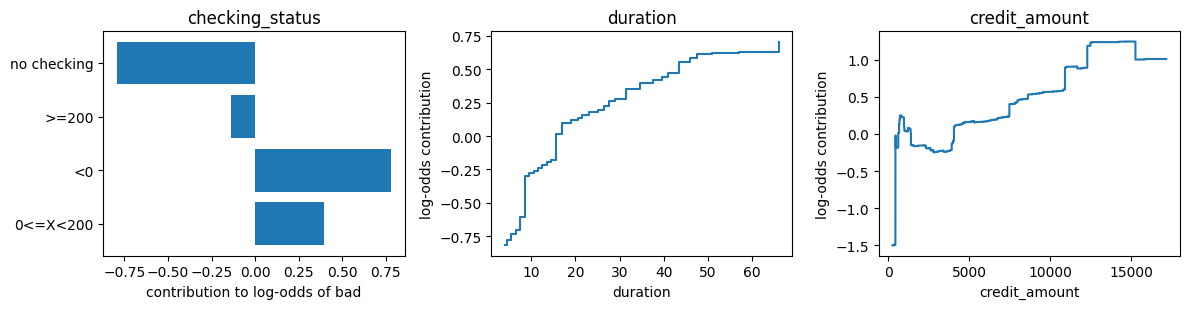

In [4]:
ebm = ExplainableBoostingClassifier(random_state=0).fit(X, y)
imp = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values(ascending=False)
print(imp.head(8).round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, name in zip(axes, ["checking_status", "duration", "credit_amount"]):
    i = ebm.term_names_.index(name)
    sc = ebm.term_scores_[i][1:-1]
    if name in CAT:
        labels = list(ebm.bins_[ebm.feature_names_in_.index(name)][0].keys())
        ax.barh(labels, sc[:len(labels)]); ax.set_xlabel("contribution to log-odds of bad")
    else:
        edges = ebm.bins_[ebm.feature_names_in_.index(name)][0]
        xs = np.r_[X[name].min(), edges]
        ax.step(xs, sc[:len(xs)], where="post"); ax.set_xlabel(name); ax.set_ylabel("log-odds contribution")
    ax.set_title(name)
plt.tight_layout(); plt.show()

**Checkpoint 4:** `checking_status` is the most important term. Its bar for `no checking` is the most negative (lowest risk), the oddity discussed in Lab 1.2 and in Chapter 5. The `duration` shape rises overall but not smoothly.

## 5. Does the reading survive resampling?

Refit the EBM on five bootstrap samples and record which three terms come out on top each time.

In [5]:
rng = np.random.default_rng(0)
tops = []
for b in range(5):
    idx = rng.integers(0, len(X), len(X))
    m = ExplainableBoostingClassifier(random_state=b).fit(X.iloc[idx], y[idx])
    s = pd.Series(m.term_importances(), index=m.term_names_).sort_values(ascending=False)
    tops.append(list(s.index[:3]))
    print(b, tops[-1])
print("terms in the top 3 every time:", set.intersection(*map(set, tops)))

0 ['checking_status', 'purpose & credit_amount', 'credit_amount & age']


1 ['checking_status', 'duration', 'purpose']


2 ['checking_status', 'credit_history', 'purpose']


3 ['checking_status', 'duration', 'savings_status']


4 ['checking_status', 'credit_amount', 'savings_status']
terms in the top 3 every time: {'checking_status'}


**Checkpoint 5:** `checking_status` is in the top three in every resample; the other places move between terms such as `duration`, `purpose`, `credit_history`, `savings_status` and even pairwise terms. Report what is stable and what is not.

## 6. A monotonicity check on the black box

Should predicted risk ever fall as loan duration grows? Compare gradient boosting with and without an increasing constraint on `duration`, by the average predicted risk over a grid of durations.

In [6]:
Xn = pd.get_dummies(X, dtype=float)
cols = list(Xn.columns)
grid = np.arange(6, 61, 1.0)
for cst in (0, 1):
    mc = [0] * len(cols); mc[cols.index("duration")] = cst
    m = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, random_state=0, monotonic_cst=mc)
    auc = cross_val_score(m, Xn, y, cv=cv, scoring="roc_auc").mean()
    m.fit(Xn, y)
    curve = np.array([m.predict_proba(Xn.assign(duration=g))[:, 1].mean() for g in grid])
    print(f"constraint={cst}: AUC {auc:.3f}; downward steps along duration: {(np.diff(curve) < -1e-4).sum()}")

constraint=0: AUC 0.780; downward steps along duration: 5


constraint=1: AUC 0.778; downward steps along duration: 0


**Checkpoint 6:** without the constraint the average risk steps down several times (five with the pinned versions) as duration grows; with it, never. The AUC changes by less than 0.01.

Now write your recommendation (see the README).